<a href="https://colab.research.google.com/github/VAdarshReddy28/MLA0204-FOML/blob/main/Practical%20problem%2020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Future Sales Prediction
Mean Absolute Error: 59.69
R2 Score: 0.99

Enter number of future months: 6

Future Sales Prediction:
Month 61: 4111.25
Month 62: 4232.31
Month 63: 4313.30
Month 64: 4345.88
Month 65: 4334.67
Month 66: 4296.03


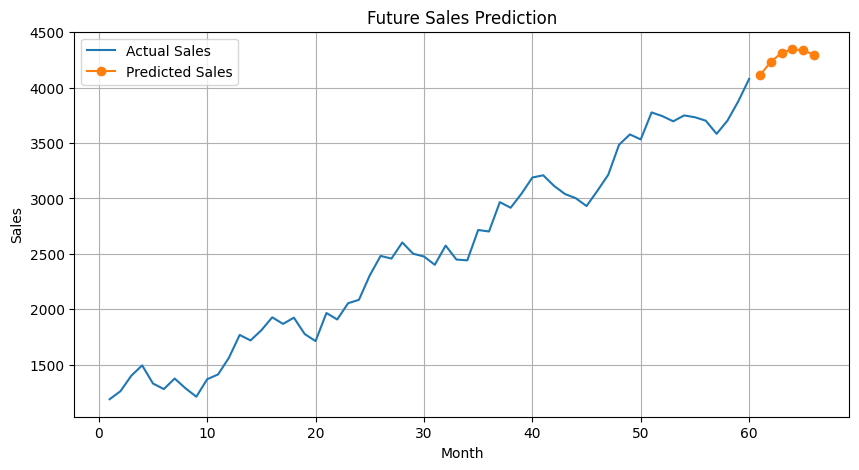

In [3]:
# SESSION 20: FUTURE SALES PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Generate historical sales dataset
np.random.seed(42)

months = np.arange(1, 61)

sales = (
    1000 +
    months * 50 +
    200 * np.sin(2 * np.pi * months / 12) +
    np.random.normal(0, 80, 60)
)

df = pd.DataFrame({
    'month': months,
    'sales': sales
})

# Prepare features
df['sin_month'] = np.sin(2 * np.pi * df['month'] / 12)
df['cos_month'] = np.cos(2 * np.pi * df['month'] / 12)

X = df[['month', 'sin_month', 'cos_month']]
y = df['sales']

# Train model
model = LinearRegression()
model.fit(X, y)

# Evaluate model on historical data
predictions = model.predict(X)

print("Future Sales Prediction")
print("Mean Absolute Error:",
      round(mean_absolute_error(y, predictions), 2))
print("R2 Score:", round(r2_score(y, predictions), 2))

# User input
n = int(input("\nEnter number of future months: "))

if n <= 0:
    print("Please enter a positive number.")
else:
    # Create future dataset
    future_months = np.arange(61, 61 + n)

    future_data = pd.DataFrame({
        'month': future_months,
        'sin_month': np.sin(2 * np.pi * future_months / 12),
        'cos_month': np.cos(2 * np.pi * future_months / 12)
    })

    # Predict future sales
    future_sales = model.predict(future_data)

    print("\nFuture Sales Prediction:")

    for month, sale in zip(future_months, future_sales):
        print(f"Month {month}: {sale:.2f}")

    # Display graph
    plt.figure(figsize=(10, 5))

    plt.plot(months, sales, label="Actual Sales")
    plt.plot(
        future_months,
        future_sales,
        marker='o',
        label="Predicted Sales"
    )

    plt.xlabel("Month")
    plt.ylabel("Sales")
    plt.title("Future Sales Prediction")
    plt.legend()
    plt.grid(True)
    plt.show()